# Lab 1.7 · Image generation inference mechanics

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Why does an image generator call its denoiser repeatedly?

A diffusion-style pipeline starts with random values. At each step the model estimates a direction for changing the current sample. A **scheduler** determines the noise levels or timesteps to visit and how to use each prediction to update the sample. The updated sample becomes the next model input. In many pipelines this loop runs on a latent grid, which is decoded into pixels at the end.

We will use a 6 × 6 pixel grid and a supplied **oracle** that knows the target. This makes the update easy to follow. A trained denoiser predicts a quantity the scheduler can use, such as noise, velocity, or a clean sample estimate. The oracle returns an update direction directly to isolate the loop. In this lab, if the current pixel is 0.8 and the oracle target is 0.2, the direction is −0.6. A step of size 0.5 produces 0.5. Repeating the same rule gives 0.35.

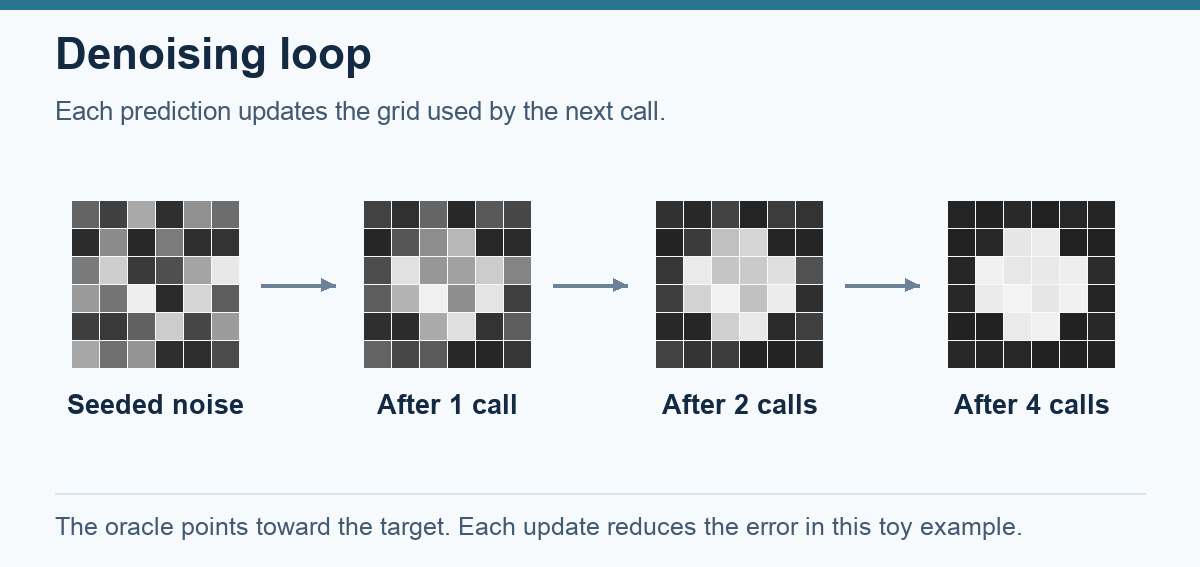

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Update a grid | Apply one predicted direction with two step sizes. | Compare the same pixel before and after the update. |
| 2. Run the loop | Feed each updated grid into the next prediction. | Inspect the snapshots, error, and number of model calls. |

In [ ]:
from random import Random
from statistics import mean

target = [[float(c == "#") for c in row] for row in
          ["......", "..##..", ".####.", ".####.", "..##..", "......"]]
rng = Random(7)
initial = [[rng.random() for _ in row] for row in target]

def predict_direction(grid, goal):
    return [[b - a for a, b in zip(row, target_row)]
            for row, target_row in zip(grid, goal)]

def error(grid):
    return mean(abs(a - b) for row, goal in zip(grid, target)
                for a, b in zip(row, goal))

def show(grid):
    palette = " .:-=+*#%@"
    print("\n".join("".join(palette[round(value * 9)] for value in row) for row in grid))

print("Initial grid")
show(initial)

## Exercise 1. Apply one update

Return a new grid. For every pixel, add the step size times the predicted direction to its current value. Try the 0.25 and 0.75 updates from the same starting grid. Predict which moves closer to the target.

In [ ]:
def update(grid, direction, step_size):
    return None

In [ ]:
from math import isclose

if update([[0.8]], [[-0.6]], 0.5) is not None:
    assert isclose(update([[0.8]], [[-0.6]], 0.5)[0][0], 0.5)
    direction = predict_direction(initial, target)
    for size in (0.25, 0.75):
        sample = update(initial, direction, size)
        print("Step:", size, "first pixel:", round(sample[0][0], 3),
              "mean absolute error:", round(error(sample), 3))
    assert error(update(initial, direction, 0.75)) < error(update(initial, direction, 0.25))
    print("PASS — the larger update moves farther in the predicted direction")

## Exercise 2. Run the denoising loop

Keep the initial grid as snapshot zero. For each step size, recompute the direction using the current grid and append the next grid. The predictor should run once per step. Each update must create a new grid so earlier snapshots stay intact.

In [ ]:
def denoise(start, goal, step_sizes):
    return None

In [ ]:
check_passed = False
if update([[0.8]], [[-0.6]], 0.5) is not None:
    history = denoise(initial, target, [0.5] * 4)
    if history is not None:
        assert len(history) == 5 and history[0] == initial
        assert all(isclose(error(b), error(a) / 2) for a, b in zip(history, history[1:]))
        for index, grid in enumerate(history):
            print("Model calls:", index, "error:", round(error(grid), 3))
            show(grid)
        print("PASS — each step uses the updated sample")
        check_passed = True
if not check_passed:
    print("Complete update and denoise and rerun the checks in order.")

## Optional extension · Guidance and model evaluations

Kiely contrasts the full-grid update of image denoising with the token-by-token loop in the LLM labs. He also describes **classifier-free guidance**, where a denoising step can evaluate both a conditional and an unconditional prediction. With the convention used here, the guided direction is `unconditional + scale × (conditional − unconditional)`. At scale 0 it equals the unconditional direction, and at scale 1 it equals the conditional direction. A runtime may batch both predictions into one call, so count prediction branches separately from Python calls or elapsed time. A negative prompt can supply the baseline conditioning in pipelines that support it.

The oracle loop above uses one prediction per step. The extension below isolates guidance at a single cell and accounts for the extra branch.

For unconditional direction −0.2 and conditional direction 0.1, predict the result at scales 0, 1, and 2. Change the scale and compare to the original predictions. How many branch evaluations would your four-step loop require with both branches enabled on every step?

Predict the result before you run the cell.

**Reading** · Philip Kiely, *Inference Engineering*, §2.3, pp. 55–56.

In [ ]:
from math import isclose

unconditional, conditional = -0.2, 0.1
guided = [unconditional + scale * (conditional - unconditional)
          for scale in (0, 1, 2)]
assert all(isclose(a, b) for a, b in zip(guided, [-0.2, 0.1, 0.4]))
print("Directions at scales 0, 1, 2:", [round(x, 2) for x in guided])
print("Prediction branches over four guided updates:", 4 * 2)

## Wrap-up

Try step sizes [0.1, 0.2, 0.4, 0.8]. Which snapshots look different? Why does the error here tell you only about the oracle experiment, not the perceptual quality of generated images?

## Optional system exercise · Accounting for guidance work

A trace shows 20 scheduler steps and 20 batched denoiser calls, each containing a conditional and a baseline prediction. Report the step count, call count, and number of prediction branches separately. Which would you pair with measured time to compare another runtime?